# Session 2: Normal Distribution Probabilities

*ECE 225A, Module 04 (The Normal Distribution), deck 8.Normal_distribution-probabilities, slides 1-17*

Session 1 established the normal density. To use it, we need probabilities of intervals, and those require the CDF, which has no closed form. This looks like a serious problem, since it seems that a separate table is needed for every $\mu$ and $\sigma$. It is not. One table for the standard normal, covering only nonnegative values, is enough: symmetry handles the negative values, and standardizing handles every other normal. The second half of the session draws the main conclusion of this reduction. For a normal variable, the chance of landing within $\alpha$ standard deviations of the mean depends only on $\alpha$, which gives the 68-95-99.7 rule and a sense of how rare far-out values really are.

## Learning objectives

After this session you should be able to:

1. Define $\Phi(z)$, explain why it needs a table or program, and read values from the Z table.
2. Compute $P(Z \le a)$, $P(Z \ge a)$, and $P(a \le Z \le b)$, for positive and negative $a$ and $b$, using $\Phi(-a) = 1 - \Phi(a)$.
3. Standardize any $X \sim N(\mu, \sigma^2)$ to a Z score, and use it to compute interval probabilities.
4. Explain why $P(\lvert X - \mu \rvert \ge \sigma)$ varies across distributions, but not across normal distributions.
5. Bound $P(\lvert Z \rvert \le 1)$ by simple areas, and derive the 68-95-99.7 rule from the table.
6. Convert tail probabilities into expected waiting times, and explain the idea behind six sigma.

## Prerequisites

- The CDF and interval probabilities for continuous variables (Module 01, Session 5).
- The normal density, its symmetry, and $aX + b \sim N(a\mu + b, a^2\sigma^2)$ (Session 1).
- The mean $1/p$ of a geometric waiting time (Module 01, Session 5).

In [1]:
from math import e, exp, pi, sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(225)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, FAINT, GRID = "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})

Phi, phi = norm.cdf, norm.pdf

## 1. The cumulative distribution function (slides 1-2)

Intervals come in three types: **less** ($X \le a$), **more** ($X \ge b$), and **between** ($a \le X \le b$). A single function determines the probabilities of all of them, the **cumulative distribution function**:

$$F(x) \triangleq P(X \le x) = \int_{-\infty}^{x} f(u)\, du.$$

## 2. The normal CDF (slide 3)

For $X \sim N_{\mu,\sigma^2}$,

$$F_{\mu,\sigma^2}(x) \triangleq P(X \le x) = \int_{-\infty}^{x} \frac{1}{\sqrt{2\pi\sigma^2}}\, e^{-\frac{(u - \mu)^2}{2\sigma^2}}\, du.$$

Two worries arise:

1. **No closed form.** $e^{-x^2}$ has no elementary antiderivative, so we need a program or a table.
2. **One for each $\mu, \sigma$?** Since those parameters vary continuously, this would be hopeless.

The second worry disappears: **one CDF determines all $F_{\mu,\sigma}$**, namely the standard normal CDF,

$$F_{0,1}(z) = P(Z \le z) = \int_{-\infty}^{z} \phi(u)\, du = \int_{-\infty}^{z} \frac{1}{\sqrt{2\pi}}\, e^{-u^2/2}\, du \triangleq \Phi(z).$$

The capital letter marks the step from the density $\phi$ to its integral $\Phi$. (The slide's exponent here still shows $(u - \mu)^2$, which should read $u^2$.)

## 3. The Z table (slide 4)

$\Phi$ has no known formula, so we use a table or a computer. The **standard normal table**, or **Z table**, lists $\Phi(z)$ for $z \ge 0$. A row gives the first decimal, and a column gives the second:

| Value | Row and column | Entry |
|---|---|---|
| $\Phi(0)$ | $0.0$ and $.00$ | $.5000$ |
| $\Phi(1.4)$ | $1.4$ and $.00$ | $.9192$ |
| $\Phi(1.82)$ | $1.8$ and $.02$ | $.9656$ |
| $\Phi(3.49)$ | $3.4$ and $.09$ | $.9998$ |

In [2]:
for z in [0, 1.4, 1.82, 3.49]:
    print(f"Phi({z:<4}) = {Phi(z):.4f}")

# The upper-left corner of the table, built from the program.
print("\n  z  " + "".join(f"  .{c:02d}  " for c in range(5)))
for r in [0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]:
    print(f"{r:4.1f} " + "".join(f" {Phi(r + c / 100):.4f}" for c in range(5)))

Phi(0   ) = 0.5000
Phi(1.4 ) = 0.9192
Phi(1.82) = 0.9656
Phi(3.49) = 0.9998

  z    .00    .01    .02    .03    .04  
 0.0  0.5000 0.5040 0.5080 0.5120 0.5160
 0.5  0.6915 0.6950 0.6985 0.7019 0.7054
 1.0  0.8413 0.8438 0.8461 0.8485 0.8508
 1.5  0.9332 0.9345 0.9357 0.9370 0.9382
 2.0  0.9772 0.9778 0.9783 0.9788 0.9793
 2.5  0.9938 0.9940 0.9941 0.9943 0.9945
 3.0  0.9987 0.9987 0.9987 0.9988 0.9988


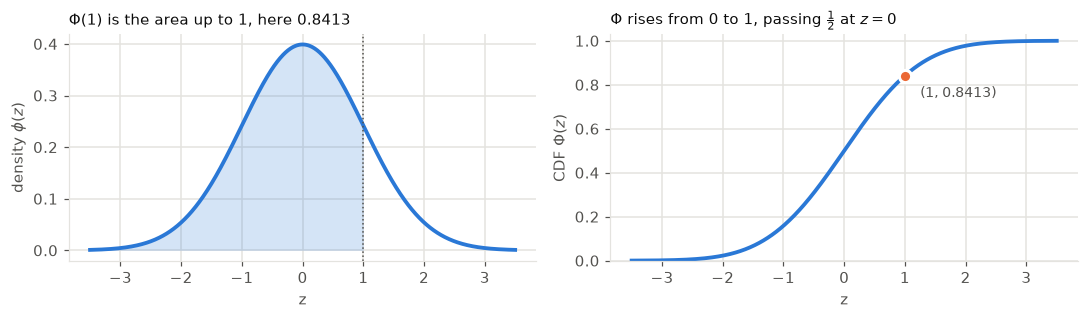

In [3]:
zs = np.linspace(-3.5, 3.5, 701)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
a = 1.0

axes[0].plot(zs, phi(zs), color=BLUE, lw=2.5)
axes[0].fill_between(zs, phi(zs), where=zs <= a, color=BLUE, alpha=0.2, lw=0)
axes[0].axvline(a, color=MUTED, lw=1, ls=":")
axes[0].set(xlabel="z", ylabel=r"density $\phi(z)$")
axes[0].set_title(rf"$\Phi({a:g})$ is the area up to {a:g}, here {Phi(a):.4f}", color=INK, loc="left", fontsize=10)

axes[1].plot(zs, Phi(zs), color=BLUE, lw=2.5)
axes[1].plot([a], [Phi(a)], "o", color=ORANGE, ms=8, mec="white", mew=2, zorder=3)
axes[1].annotate(f"({a:g}, {Phi(a):.4f})", (a, Phi(a)), xytext=(10, -14), textcoords="offset points", color=MUTED, fontsize=9)
axes[1].set(xlabel="z", ylabel=r"CDF $\Phi(z)$", ylim=(0, 1.03))
axes[1].set_title(r"$\Phi$ rises from 0 to 1, passing $\frac{1}{2}$ at $z = 0$", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 4. Using the Z table (slide 5)

Let $Z \sim N(0, 1)$. For nonnegative values the table is direct:

| Event | Probability | Example with the table |
|---|---|---|
| $Z \le a$ | $\Phi(a)$ | $P(Z \le 1) = \Phi(1) \approx 0.84$ |
| $Z \ge a$ | $1 - \Phi(a)$ | $P(Z \ge 1) \approx 1 - 0.84 = 0.16$ |
| $a \le Z \le b$ | $\Phi(b) - \Phi(a)$ | $P(1 \le Z \le 2) \approx 0.9772 - 0.8413 = 0.1359$ |

What about $P(Z \le -1)$, that is, $\Phi(-1)$? The table has no such row.

## 5. Quiz: the missing half (slide 6)

**Question.** The table gives $\Phi(a)$ for $a \ge 0$. What about $a < 0$?

**A warm-up.** Take a density $f$ with CDF $F$, and suppose $F(2) = 0.6$. What can we say about $F(-2)$? For an arbitrary density, only that $0 \le F(-2) \le F(2) = 0.6$.

**If $f$ is symmetric around 0,** we can say exactly what it is:

$$F(-2) = P(X \le -2) = P(X \ge 2) = 1 - F(2) = 0.4.$$

So for a symmetric density, $F(a)$ determines $F(-a)$ for every $a > 0$. Since $\phi$ is symmetric around 0, the positive half of $\Phi$ determines the negative half. The missing half is no longer missing.

## 6. $\Phi$ of negative values (slide 7)

For $a \ge 0$, reflect, and then take the complement:

$$\Phi(-a) = P(Z \le -a) = P(Z \ge a) = 1 - P(Z \le a) = 1 - \Phi(a).$$

So $\Phi(-1) = 1 - \Phi(1) \approx 1 - 0.84 = 0.16$. By symmetry, the identity holds for all $a$:

$$\boxed{\Phi(-a) = 1 - \Phi(a).}$$

## 7. Negative Z values (slide 8)

The three cases now become:

| Event | Probability | Example |
|---|---|---|
| $Z \le -a$ | $\Phi(-a) = 1 - \Phi(a)$ | $P(Z \le -1) \approx 0.16$ |
| $Z \ge -a$ | $1 - \Phi(-a) = \Phi(a)$ | $P(Z \ge -1) = \Phi(1) \approx 0.84$ |
| $-a \le Z \le b$ | $\Phi(b) - \Phi(-a) = \Phi(a) + \Phi(b) - 1$ | $P(-1 \le Z \le 2) \approx 0.8185$ |

In [4]:
Z = rng.standard_normal(4_000_000)
checks = [
    ("P(Z <= 1)", Phi(1), np.mean(Z <= 1)),
    ("P(Z >= 1)", 1 - Phi(1), np.mean(Z >= 1)),
    ("P(1 <= Z <= 2)", Phi(2) - Phi(1), np.mean((Z >= 1) & (Z <= 2))),
    ("P(Z <= -1) = 1 - Phi(1)", 1 - Phi(1), np.mean(Z <= -1)),
    ("P(Z >= -1) = Phi(1)", Phi(1), np.mean(Z >= -1)),
    ("P(-1 <= Z <= 2) = Phi(1) + Phi(2) - 1", Phi(1) + Phi(2) - 1, np.mean((Z >= -1) & (Z <= 2))),
]
for name, exact, sim in checks:
    print(f"{name:40} exact {exact:.4f}, simulated {sim:.4f}")

P(Z <= 1)                                exact 0.8413, simulated 0.8413
P(Z >= 1)                                exact 0.1587, simulated 0.1587
P(1 <= Z <= 2)                           exact 0.1359, simulated 0.1361
P(Z <= -1) = 1 - Phi(1)                  exact 0.1587, simulated 0.1588
P(Z >= -1) = Phi(1)                      exact 0.8413, simulated 0.8412
P(-1 <= Z <= 2) = Phi(1) + Phi(2) - 1    exact 0.8186, simulated 0.8186


## 8. The general normal (slide 9)

Typically $X \sim N_{\mu,\sigma^2}$, with $\mu$ and $\sigma^2$ known. To reach the table, convert $X$ to a standard $Z$ in two steps:

| Variable | $E$ | $V$ |
|---|---|---|
| $X$ | $\mu$ | $\sigma^2$ |
| $X - \mu$ | $0$ | $\sigma^2$ |
| $\dfrac{X - \mu}{\sigma}$ | $0$ | $1$ |

A linear transform of a normal is normal, so the last line is exactly standard normal:

$$Z \triangleq \frac{X - \mu}{\sigma} \sim N_{0,1}.$$

This $Z$ is the **Z score of $X$**, or the **standardized version of $X$**. It says how many standard deviations $X$ lies above its mean. Apply the same steps to all three parts of an inequality:

$$P(a \le X \le b) = P(a - \mu \le X - \mu \le b - \mu) = P\left(\frac{a - \mu}{\sigma} \le \frac{X - \mu}{\sigma} \le \frac{b - \mu}{\sigma}\right) = P\left(\frac{a - \mu}{\sigma} \le Z \le \frac{b - \mu}{\sigma}\right).$$

So **one table works for every normal**.

## 9. Example: general to standard (slide 10)

**Problem.** Let $X \sim N(15, 4)$, so $\mu = 15$ and $\sigma = 2$. Find $P(11 \le X \le 17)$.

**Solution.** The Z score is $Z = \frac{X - 15}{2}$. Note that the lower limit gives a negative value, since $11 < \mu$:

$$P(11 \le X \le 17) = P\left(\frac{11 - 15}{2} \le Z \le \frac{17 - 15}{2}\right) = P(-2 \le Z \le 1) = \Phi(1) - \Phi(-2).$$

With $\Phi(-2) = 1 - \Phi(2)$,

$$= \Phi(1) + \Phi(2) - 1 \approx 0.8413 + 0.9772 - 1 = 0.8185.$$

In [5]:
mu, sigma = 15, 2
a, b = 11, 17
X = rng.normal(mu, sigma, size=4_000_000)

za, zb = (a - mu) / sigma, (b - mu) / sigma
print(f"z limits: {za}, {zb}")
print(f"from the table: {0.8413 + 0.9772 - 1:.4f}")
print(f"from the program: {Phi(zb) - Phi(za):.4f}")
print(f"direct, without standardizing: {norm(mu, sigma).cdf(b) - norm(mu, sigma).cdf(a):.4f}")
print(f"simulated: {np.mean((X >= a) & (X <= b)):.4f}")

z limits: -2.0, 1.0
from the table: 0.8185
from the program: 0.8186
direct, without standardizing: 0.8186
simulated: 0.8187


## 10. Deviation from the mean (slides 11-12)

The standard deviation $\sigma$ is roughly the expected deviation from the mean. So how likely is a deviation of at least $\sigma$? In general, $P(\lvert X - \mu \rvert \ge \sigma)$ **varies for different distributions**, by as much as it possibly can.

**Two spikes.** $p(x) = \frac{1}{2}$ at $x = 1$ and at $x = -1$. Then $\mu = 0$ and $\sigma = 1$, and every value deviates by exactly $\sigma$:

$$P(\lvert X - \mu \rvert \ge \sigma) = 1.$$

**Three spikes.** With $n$ large (say 100),

$$p(x) = \begin{cases} \frac{1}{2n^2} & x = \pm n \\ 1 - \frac{1}{n^2} & x = 0. \end{cases}$$

Again $\mu = 0$, and $V = 2 \cdot \frac{1}{2n^2} \cdot n^2 = 1$, so $\sigma = 1$. But now

$$P(\lvert X - \mu \rvert \ge \sigma) = \frac{1}{n^2} \approx 0.$$

The same $\mu$ and $\sigma$ give opposite answers. (A callout on the slide writes the two-spike event as $P(\lvert X \rvert > 1)$. It should be $\ge$, because there $\lvert X \rvert$ always equals exactly 1.)

What about the normal distribution?

In [6]:
def deviation_prob(values, probs):
    values, probs = np.array(values, float), np.array(probs, float)
    mu = np.sum(values * probs)
    sigma = sqrt(np.sum((values - mu) ** 2 * probs))
    return mu, sigma, np.sum(probs[np.abs(values - mu) >= sigma - 1e-12])


m, s, pr = deviation_prob([-1, 1], [0.5, 0.5])
print(f"two spikes:             mu = {m:.1f}, sigma = {s:.1f}, P(|X - mu| >= sigma) = {pr:.6f}")
for n in [2, 10, 100]:
    m, s, pr = deviation_prob([-n, 0, n], [1 / (2 * n ** 2), 1 - 1 / n ** 2, 1 / (2 * n ** 2)])
    print(f"three spikes, n = {n:<4}:  mu = {m:.1f}, sigma = {s:.1f}, P(|X - mu| >= sigma) = {pr:.6f}")
print(f"\nany normal:             P(|X - mu| >= sigma) = {2 * norm.sf(1):.4f}")

two spikes:             mu = 0.0, sigma = 1.0, P(|X - mu| >= sigma) = 1.000000
three spikes, n = 2   :  mu = 0.0, sigma = 1.0, P(|X - mu| >= sigma) = 0.250000
three spikes, n = 10  :  mu = 0.0, sigma = 1.0, P(|X - mu| >= sigma) = 0.010000
three spikes, n = 100 :  mu = 0.0, sigma = 1.0, P(|X - mu| >= sigma) = 0.000100

any normal:             P(|X - mu| >= sigma) = 0.3173


## 11. Normal deviation (slide 13)

For $X \sim N_{\mu,\sigma^2}$, is $P(\lvert X - \mu \rvert \ge \alpha\sigma)$ different for every Gaussian? **No.** How does it change with $\mu$ and $\sigma$? **It doesn't.** Standardizing shows why:

$$P(\lvert X - \mu \rvert \le \alpha\sigma) = P(\mu - \alpha\sigma \le X \le \mu + \alpha\sigma) = P\left(-\alpha \le \frac{X - \mu}{\sigma} \le \alpha\right) = P(-\alpha \le Z \le \alpha).$$

$\mu$ and $\sigma$ have vanished. The probability **depends only on $\alpha$**, the number of standard deviations. This is a fundamental property of normal distributions, and it applies equally to height, weight, and rainfall.

In [7]:
print("(mu, sigma)         alpha = 1   alpha = 2   alpha = 3")
for mu, sigma in [(0, 1), (170, 8), (-40, 0.1), (5000, 900)]:
    X = rng.normal(mu, sigma, size=2_000_000)
    row = [np.mean(np.abs(X - mu) <= k * sigma) for k in (1, 2, 3)]
    print(f"({mu:>5}, {sigma:>5})      " + "    ".join(f"{v:.4f}" for v in row))
print("from the table:     " + "    ".join(f"{2 * Phi(k) - 1:.4f}" for k in (1, 2, 3)))

(mu, sigma)         alpha = 1   alpha = 2   alpha = 3
(    0,     1)      0.6829    0.9545    0.9973
(  170,     8)      0.6823    0.9545    0.9973


(  -40,   0.1)      0.6826    0.9546    0.9973


( 5000,   900)      0.6823    0.9545    0.9973
from the table:     0.6827    0.9545    0.9973


## 12. A simple estimate: one $\sigma$ (slide 14)

Before opening the table, we can estimate $P(\lvert X - \mu \rvert \le \sigma) = P(\lvert Z \rvert \le 1)$ using only areas we can compute by hand. On $[-1, 1]$, the density runs between

$$\phi(1) = \frac{1}{\sqrt{2\pi e}} \quad \text{at the ends} \qquad \text{and} \qquad \phi(0) = \frac{1}{\sqrt{2\pi}} \quad \text{in the middle.}$$

**Two rectangles.** The area lies between rectangles of width 2 at those two heights:

$$0.48 \approx \sqrt{\frac{2}{\pi e}} \le P(\lvert X - \mu \rvert \le \sigma) \le \sqrt{\frac{2}{\pi}} \approx 0.8.$$

**A house.** The slide asks "how big's your house?" A house of width $a$, with walls of height $b$ and a roof peak at height $c$, has area

$$ab + \frac{a(c - b)}{2} = \frac{ab + ac}{2},$$

the average of the two rectangles. Here that average is

$$0.64 \approx \frac{\sqrt{2/(\pi e)} + \sqrt{2/\pi}}{2} \le P(\lvert X - \mu \rvert \le \sigma).$$

Why is this a lower bound? On $[-1, 1]$ the bell is concave, since its inflection points are at $\pm 1$ (Session 1). So the curve bulges above the straight roof, and the true area exceeds the house. For a more precise answer, we use the Z table.

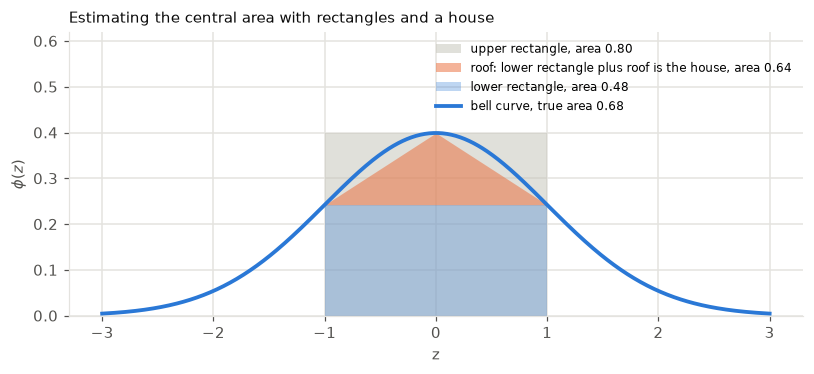

lower rectangle sqrt(2/(pi e)) = 0.4839
upper rectangle sqrt(2/pi)     = 0.7979
house (their average)          = 0.6409
true P(|Z| <= 1)               = 0.6827


In [8]:
zs = np.linspace(-3, 3, 601)
low, high = phi(1), phi(0)

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.fill_between([-1, 1], high, color=FAINT, alpha=0.5, lw=0, label=f"upper rectangle, area {2 * high:.2f}")
ax.fill_between([-1, 0, 1], [low, low, low], [low, high, low], color=ORANGE, alpha=0.5, lw=0, label=f"roof: lower rectangle plus roof is the house, area {low + high:.2f}")
ax.fill_between([-1, 1], low, color=BLUE, alpha=0.3, lw=0, label=f"lower rectangle, area {2 * low:.2f}")
ax.plot(zs, phi(zs), color=BLUE, lw=2.5, label=f"bell curve, true area {2 * Phi(1) - 1:.2f}")
ax.set(xlabel="z", ylabel=r"$\phi(z)$", ylim=(0, 0.62))
ax.legend(frameon=False, loc="upper right", fontsize=8)
ax.set_title("Estimating the central area with rectangles and a house", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

print(f"lower rectangle sqrt(2/(pi e)) = {sqrt(2 / (pi * e)):.4f}")
print(f"upper rectangle sqrt(2/pi)     = {sqrt(2 / pi):.4f}")
print(f"house (their average)          = {(sqrt(2 / (pi * e)) + sqrt(2 / pi)) / 2:.4f}")
print(f"true P(|Z| <= 1)               = {2 * Phi(1) - 1:.4f}")

## 13. The 68-95-99.7 rule (slide 15)

For a precise answer, standardize and use $\Phi(-a) = 1 - \Phi(a)$:

$$P(\lvert X - \mu \rvert \le \alpha\sigma) = P(-\alpha \le Z \le \alpha) = \Phi(\alpha) - \Phi(-\alpha) = \Phi(\alpha) - [1 - \Phi(\alpha)] = 2\Phi(\alpha) - 1.$$

| $\alpha$ | $\Phi(\alpha) \approx$ | $2\Phi(\alpha) - 1 \approx$ |
|---|---|---|
| 1 | 0.8413 | $2(0.8413) - 1 = 0.6826$ |
| 2 | 0.9772 | $2(0.9772) - 1 = 0.9544$ |
| 3 | 0.9987 | $2(0.9987) - 1 = 0.9974$ |

This is the **68-95-99.7 rule**, also called the empirical rule or the $3\sigma$ rule: about 68% of a normal population lies within one standard deviation of the mean, about 95% within two, and about 99.7% within three.

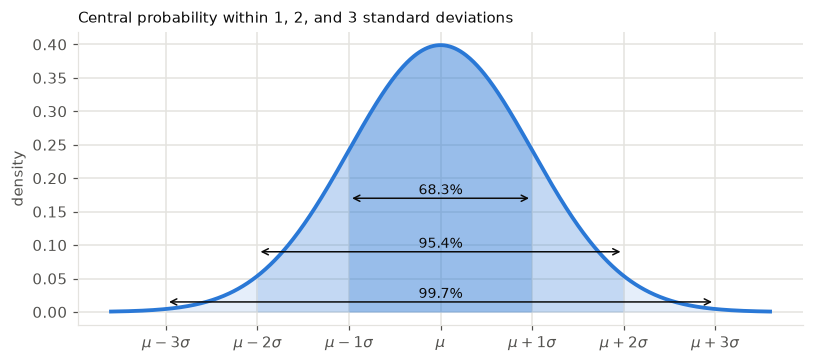

In [9]:
zs = np.linspace(-3.6, 3.6, 721)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(zs, phi(zs), color=BLUE, lw=2.5)
for k, alpha in [(3, 0.12), (2, 0.18), (1, 0.28)]:
    ax.fill_between(zs, phi(zs), where=np.abs(zs) <= k, color=BLUE, alpha=alpha, lw=0)
for k, height in [(1, 0.17), (2, 0.09), (3, 0.015)]:
    ax.annotate("", xy=(-k, height), xytext=(k, height), arrowprops=dict(arrowstyle="<->", color=INK, lw=1))
    ax.annotate(f"{2 * Phi(k) - 1:.1%}", (0, height + 0.006), ha="center", color=INK, fontsize=9)
ax.set_xticks(range(-3, 4))
ax.set_xticklabels([rf"$\mu {s:+d}\sigma$" if s else r"$\mu$" for s in range(-3, 4)])
ax.set(ylabel="density")
ax.set_title("Central probability within 1, 2, and 3 standard deviations", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 14. Rare events (slide 16)

How rare are values far from the mean? Suppose you take one normal sample per day. Each day is independent, with probability $p = P(\lvert X - \mu \rvert > \alpha\sigma)$ of landing outside. The wait for the first such day is geometric, with mean $1/p$ days.

| $\alpha$ | $P(\lvert X - \mu \rvert \le \alpha\sigma)$ | $P(\lvert X - \mu \rvert > \alpha\sigma)$ | Expected time to the first such day |
|---|---|---|---|
| 1 | 68.2% | 31.8% | 3 days |
| 2 | 95.4% | 4.6% | 3 weeks |
| 3 | 99.7% | 0.3% | 1 year |
| 4 | 99.99% | 0.01% | 43 years |
| 5 | 99.9999% | $10^{-6}$ | 4776 years |
| 6 | 99.9999998% | $2 \cdot 10^{-9}$ | 1.3 million years |

The probabilities fall much faster than exponentially in $\alpha$. This is the point of the **six sigma** philosophy in quality control: set tolerances so wide, compared to the process's $\sigma$, that a defect essentially never happens.

The output below gives the exact values. The slide's table rounds its middle column heavily, since the exact tails at $\alpha = 4$ and $5$ are about $6.3 \cdot 10^{-5}$ and $5.7 \cdot 10^{-7}$. Its last entry, 1.3 million years, is closer to 1.4 million, and its $\alpha = 5$ entry comes out about 4779 years with 365-day years.

The closing joke of the slide is that life is normal, unless it is ab-normal: some real data have much heavier tails than the bell curve, so such small numbers should be trusted only as far as the model is.

In [10]:
print("alpha   P(outside)      days             years")
for a in range(1, 7):
    p = 2 * norm.sf(a)
    print(f"{a:4}    {p:.4e}   {1 / p:14,.1f}   {1 / p / 365:14,.2f}")

# A direct check of the waiting-time claim at alpha = 2.
p = 2 * norm.sf(2)
days = rng.geometric(p, size=1_000_000)
print(f"\nalpha = 2, simulated mean wait: {days.mean():.2f} days, exact 1/p = {1 / p:.2f} days")

alpha   P(outside)      days             years
   1    3.1731e-01              3.2             0.01
   2    4.5500e-02             22.0             0.06
   3    2.6998e-03            370.4             1.01
   4    6.3342e-05         15,787.2            43.25
   5    5.7330e-07      1,744,277.9         4,778.84
   6    1.9732e-09    506,797,345.9     1,388,485.88

alpha = 2, simulated mean wait: 22.00 days, exact 1/p = 21.98 days


## 15. Summary (slide 17)

| Topic | Result |
|---|---|
| Interval probabilities | Come from the CDF |
| Standard normal CDF | $\Phi(z) = \frac{1}{\sqrt{2\pi}} \int_{-\infty}^{z} e^{-u^2/2}\, du$, with no closed form |
| Computing $\Phi$ | A program, or the Z table for positive values |
| Negative values | $\Phi(-a) = 1 - \Phi(a)$ |
| General normal | Z score $\frac{X - \mu}{\sigma} \sim N(0, 1)$, and then the table |
| Normal deviation | $P(\lvert X - \mu \rvert \le \alpha\sigma)$ is determined by $\alpha$ alone, hence the 68-95-99.7 rule |
| Far from the mean | $P(\lvert X - \mu \rvert > \alpha\sigma)$ falls rapidly with $\alpha$, hence six sigma |

## Common pitfalls

1. **Using the variance in place of $\sigma$ in a Z score.** For $N(15, 4)$, divide by 2, not by 4.
2. **Forgetting which way the table reads.** The table gives the area to the *left*. So $P(Z \ge a) = 1 - \Phi(a)$, not $\Phi(a)$.
3. **Writing $\Phi(-a) = -\Phi(a)$.** A probability cannot be negative. The rule is $\Phi(-a) = 1 - \Phi(a)$.
4. **Applying the 68-95-99.7 rule to non-normal data.** The spike examples show that $P(\lvert X - \mu \rvert \ge \sigma)$ can be anywhere from about 0 to 1, for other distributions.
5. **Mixing one-sided and two-sided tails.** $P(\lvert Z \rvert > 2) \approx 4.6\%$, while $P(Z > 2) \approx 2.3\%$. Likewise $P(Z > 3) \approx 0.13\%$.
6. **Forgetting to transform both limits.** Standardize $a$ and $b$ with the same $\mu$ and $\sigma$, and keep the sign, since a limit below $\mu$ has a negative $z$.
7. **Assuming the table needs many digits at the extremes.** Tables end near $3.49$. For rare events, use a program, as in Section 14.
8. **Trusting extreme tail numbers too much.** A six sigma probability holds only if the normal model holds out there, and real data can have heavier tails.

## Key takeaways

- **One function:** $\Phi(z) = P(Z \le z)$ has no closed form, and it determines every normal CDF.
- **Reading the table:** a row for the first decimal and a column for the second, such as $\Phi(1.82) = 0.9656$.
- **Symmetry:** $\Phi(-a) = 1 - \Phi(a)$, and $P(-a \le Z \le b) = \Phi(a) + \Phi(b) - 1$.
- **Standardizing:** $Z = \frac{X - \mu}{\sigma} \sim N(0, 1)$, so $P(a \le X \le b) = \Phi\big(\frac{b - \mu}{\sigma}\big) - \Phi\big(\frac{a - \mu}{\sigma}\big)$.
- **Example:** for $X \sim N(15, 4)$, $P(11 \le X \le 17) \approx 0.8185$.
- **Deviation:** $P(\lvert X - \mu \rvert \le \alpha\sigma) = 2\Phi(\alpha) - 1$ depends on $\alpha$ only, unlike for general distributions.
- **Rule:** 68-95-99.7 for $\alpha = 1, 2, 3$. Tails then fall so quickly that a daily $6\sigma$ event takes over a million years.
- Next: Session 3 brings Gauss and Bernoulli together, and approximates binomial probabilities by normal ones.